In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_DIR = "/content/drive/MyDrive/CNN_Project"
os.makedirs(PROJECT_DIR, exist_ok=True)

print("Project folder:", PROJECT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder: /content/drive/MyDrive/CNN_Project


#Dataset Collection & Understanding

In [ ]:
#Import Libraries
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
#load dataset
transform = transforms.ToTensor()

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

100%|██████████| 170M/170M [35:22<00:00, 80.3kB/s]


Training images: 50000
Testing images: 10000


In [ ]:
#display dataset information
classes = train_dataset.classes

print("Number of classes:", len(classes))
print("Classes:", classes)

image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Image label:", classes[label])

Number of classes: 10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Image shape: torch.Size([3, 32, 32])
Image label: frog


#Exploratory Data Analysis

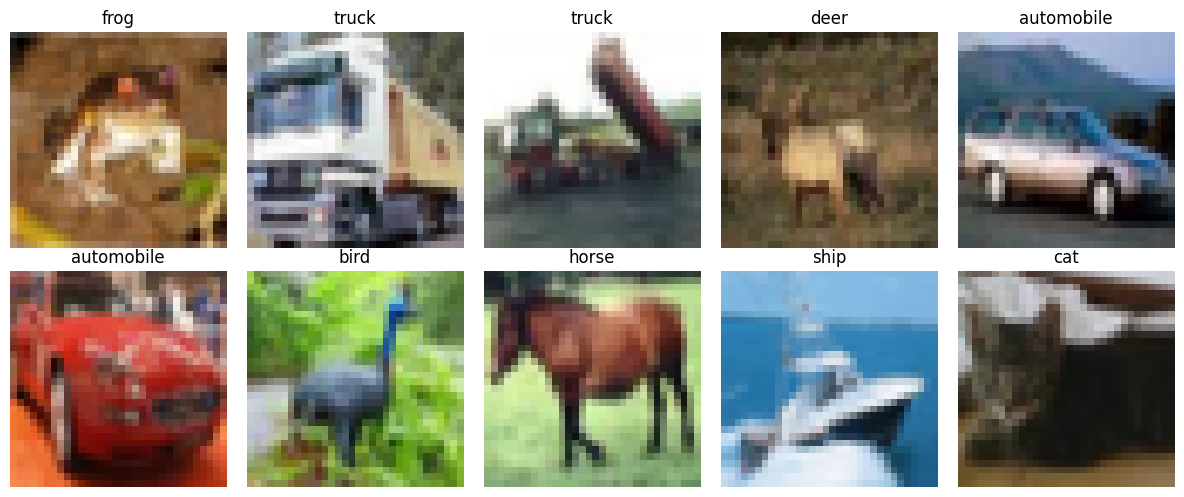

In [ ]:
#display sample images
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

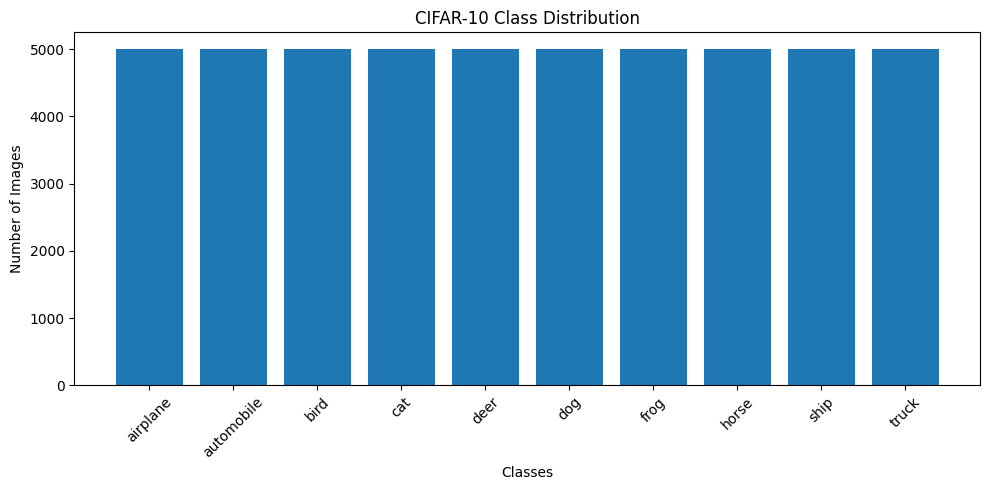

In [ ]:
#analyze class distribution
from collections import Counter

labels = train_dataset.targets
counts = Counter(labels)

plt.figure(figsize=(10, 5))
plt.bar(classes, [counts[i] for i in range(10)])

plt.xlabel("Classes")
plt.ylabel("Number of Images")
plt.title("CIFAR-10 Class Distribution")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

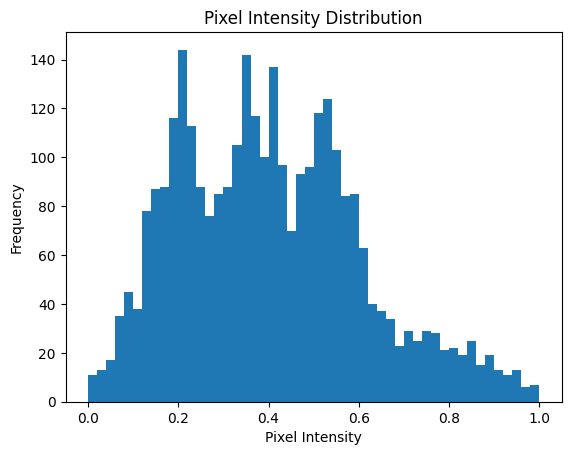

In [ ]:
#analyze pixel intensity
image, label = train_dataset[0]

plt.hist(image.numpy().flatten(), bins=50)

plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.title("Pixel Intensity Distribution")
plt.show()

#Data Preprocessing

In [ ]:
#define transformations
import torchvision.transforms as transforms

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,)*3, (0.5,)*3)
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,)*3, (0.5,)*3)
])

In [ ]:
#Load training and testing datasets
train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=test_transform
)

In [ ]:
#Create training and validation sets
from torch.utils.data import random_split, DataLoader

train_size = 45000
val_size = 5000

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_subset, batch_size=64, shuffle=True
)

val_loader = DataLoader(
    val_subset, batch_size=64, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=64, shuffle=False
)

print("Training:", len(train_subset))
print("Validation:", len(val_subset))
print("Testing:", len(test_dataset))

Training: 45000
Validation: 5000
Testing: 10000


#CNN model

In [ ]:
#define cnn model
import torch
import torch.nn as nn
import torch.nn.functional as F

class ConvNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [ ]:
#initialize the model & optimizer
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = ConvNet().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
#train cnn model
num_epochs = 10

for epoch in range(num_epochs):
    model.train()
    running_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(
        f"Epoch [{epoch+1}/{num_epochs}], "
        f"Loss: {running_loss / len(train_loader):.4f}"
    )

torch.save(
    model.state_dict(),
    f"{PROJECT_DIR}/cnn.pth"
)

print("Training complete. Model saved to Google Drive!")

Epoch [1/10], Loss: 1.5088
Epoch [2/10], Loss: 1.1723
Epoch [3/10], Loss: 1.0459
Epoch [4/10], Loss: 0.9707
Epoch [5/10], Loss: 0.9084
Epoch [6/10], Loss: 0.8621
Epoch [7/10], Loss: 0.8211
Epoch [8/10], Loss: 0.7956
Epoch [9/10], Loss: 0.7648
Epoch [10/10], Loss: 0.7440
Training complete. Model saved to Google Drive!


#Model Evaluation & Comparison

In [ ]:
#evaluate the cnn
from sklearn.metrics import accuracy_score

model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

accuracy = 100 * correct / total

print(f"CNN Test Accuracy: {accuracy:.2f}%")

CNN Test Accuracy: 75.97%


In [ ]:
#classification report
from sklearn.metrics import classification_report

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu()

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.numpy())

print(classification_report(
    all_labels,
    all_predictions,
    target_names=classes
))

              precision    recall  f1-score   support

    airplane       0.78      0.78      0.78      1000
  automobile       0.92      0.88      0.90      1000
        bird       0.68      0.67      0.67      1000
         cat       0.62      0.51      0.56      1000
        deer       0.74      0.74      0.74      1000
         dog       0.65      0.71      0.68      1000
        frog       0.63      0.91      0.75      1000
       horse       0.89      0.72      0.80      1000
        ship       0.86      0.88      0.87      1000
       truck       0.93      0.79      0.86      1000

    accuracy                           0.76     10000
   macro avg       0.77      0.76      0.76     10000
weighted avg       0.77      0.76      0.76     10000



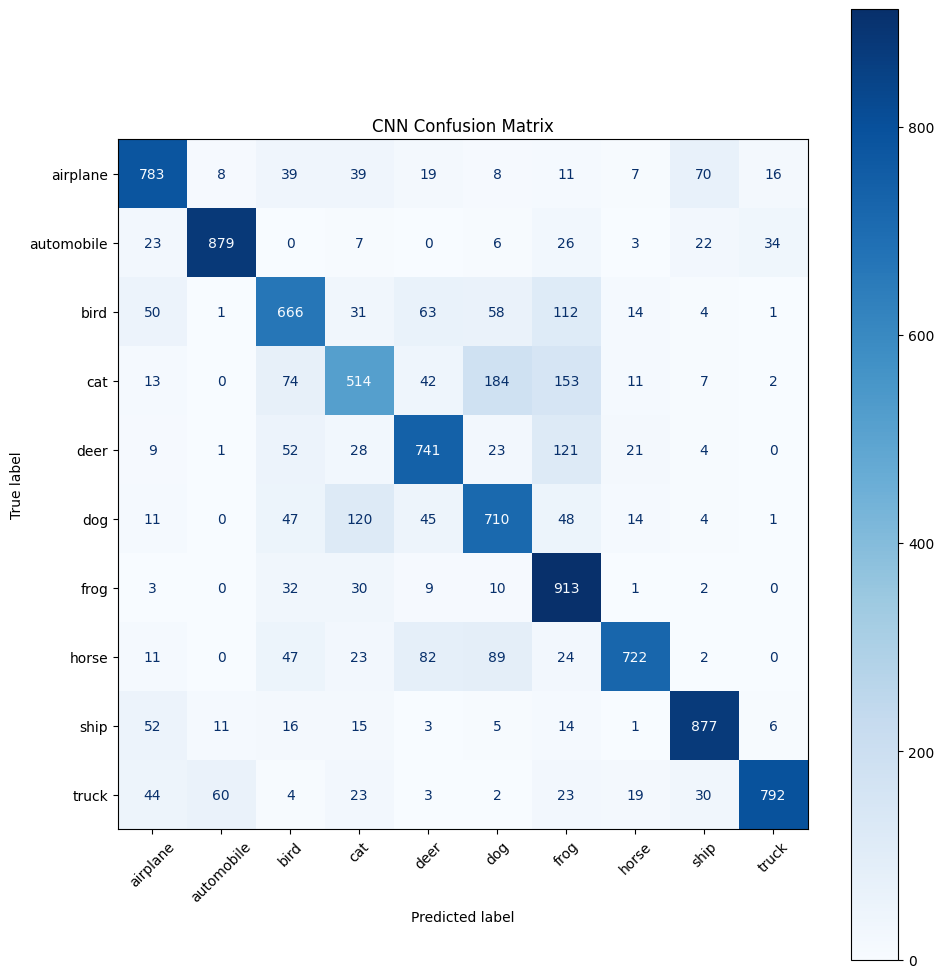

In [ ]:
#confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(all_labels, all_predictions)

fig, ax = plt.subplots(figsize=(10, 10))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

display.plot(ax=ax, xticks_rotation=45, cmap="Blues")
plt.title("CNN Confusion Matrix")
plt.tight_layout()
plt.show()

CNN Test Accuracy: 75.97%


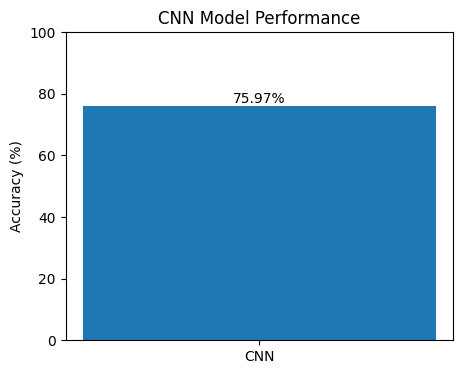

In [ ]:
#model accuracy
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

cnn_accuracy = accuracy_score(all_labels, all_predictions) * 100

print(f"CNN Test Accuracy: {cnn_accuracy:.2f}%")

plt.figure(figsize=(5, 4))
plt.bar(["CNN"], [cnn_accuracy])

plt.ylabel("Accuracy (%)")
plt.title("CNN Model Performance")
plt.ylim(0, 100)

plt.text(0, cnn_accuracy + 1, f"{cnn_accuracy:.2f}%",
         ha="center")

plt.show()

#CNN Performance Improvement

In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

#Model Saving & Prediction

In [ ]:
#load the saved model
model = ConvNet().to(device)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/CNN_Project/cnn.pth",
        map_location=device
    )
)

model.eval()

ConvNet(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(

In [ ]:
#predict an image
image, label = test_dataset[0]

with torch.no_grad():
    output = model(image.unsqueeze(0).to(device))

    probabilities = torch.softmax(output, dim=1)
    confidence, predicted = probabilities.max(dim=1)

print("Actual:", classes[label])
print("Predicted:", classes[predicted.item()])
print("Confidence:", f"{confidence.item()*100:.2f}%")

#Application Development

In [ ]:
pip install streamlit pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 63.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 45.3 MB/s eta 0:00:00


In [ ]:
%%writefile /content/drive/MyDrive/CNN_Project/app.py
import streamlit as st
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torchvision import transforms

classes = [
    "plane", "car", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Improved CNN model
class ConvNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


# Load trained model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ConvNet().to(device)
model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/CNN_Project/cnn.pth",
        map_location=device
    )
)
model.eval()

# Image preprocessing
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Streamlit interface
st.title("CIFAR-10 Image Classifier")
st.write("Upload an image to predict its category.")

uploaded_file = st.file_uploader(
    "Choose an image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:
    image = Image.open(uploaded_file).convert("RGB")
    st.image(image, caption="Uploaded Image")

    tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(tensor)
        probabilities = torch.softmax(output, dim=1)[0]

    values, indices = probabilities.topk(3)

    st.subheader("Top 3 Predictions")

    for value, index in zip(values, indices):
        st.write(
            f"**{classes[index.item()]}:** "
            f"{value.item() * 100:.2f}%"
        )

Overwriting /content/drive/MyDrive/CNN_Project/app.py


In [ ]:
import os

print(os.listdir())

['.config', 'streamlit.log', 'data', 'drive', 'sample_data']


In [ ]:
!pip install pyngrok

In [ ]:
!streamlit run /content/drive/MyDrive/CNN_Project/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
!cat /content/streamlit.log

In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token("3LEYGR0jZK72UYf0PnaizzE1Alt_3FV5cRLVE2wsesjVKDkkx")

In [ ]:
from pyngrok import ngrok

public_url = ngrok.connect(8501)
print("Your application URL:", public_url)

Your application URL: NgrokTunnel: "https://tightrope-superhero-untidy.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
#running

In [ ]:
!find /content/drive/MyDrive -name "cnn.pth" -o -name "app.py"

/content/drive/MyDrive/CNN_Project/cnn.pth
/content/drive/MyDrive/CNN_Project/app.py


In [ ]:
!pip -q install streamlit pyngrok

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 65.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 70.5 MB/s eta 0:00:00


In [ ]:
from pyngrok import ngrok
import subprocess
import getpass
import time

# Stop any previous ngrok agent
ngrok.kill()

# Enter your ngrok authentication token
ngrok.set_auth_token(getpass.getpass("Enter ngrok token: "))

# Start Streamlit
app_path = "/content/drive/MyDrive/CNN_Project/app.py"

process = subprocess.Popen([
    "streamlit", "run", app_path,
    "--server.port", "8501",
    "--server.address", "0.0.0.0",
    "--server.headless", "true"
])

time.sleep(5)

# Create a new public tunnel
public_url = ngrok.connect(8501)

print("Your website is running at:")
print(public_url)

Enter ngrok token: ··········
Your website is running at:
NgrokTunnel: "https://tightrope-superhero-untidy.ngrok-free.dev" -> "http://localhost:8501"
